# Бустинги

### 1. Бэггинг и бустинг: идеи подходов

Основная идея **бэггинга** состоит в том, чтобы агрегировать ответы большого числа независимых переобученных моделей, имеющих низкое смещение и большую дисперсию. Агрегация позволяет добиться значительного снижения дисперсии при сохранении низкого смещения. Бэггинг над деревьями, в котором при построении каждого дерева при разбиениях используются случайные подмножества признаков, называется **случайным лесом**.

Идея бустинга заключается в последовательном построении алгоритмов, каждый из которых учитывает ошибки построенной до сих пор композиции.

$$
    \sum_{i = 1}^{\ell}
        L(y_i, a_{N - 1}(x_i) + \gamma_N b_N(x_i))
    \to
    \min_{b_N, \gamma_N}
$$



#### 1.1 Простой пример.

Пусть мы решаем задачу регрессии на тренировочной выборке $(X, y)$. Мы обучаем модель $a(X)$, которая является композицией базовых моделей $b_n(X)$. Будем считать, что композиция строится простым суммированием ответов базовых моделей:

$$
a(X) = \sum_{n = 1}^{k} b_n(X).
$$

В качестве базовой модели будем использовать решающее дерево глубины один (decision stump).

Будем решать задачу при помощи минимизации среднеквадратичной ошибки:

$$
\dfrac{1}{\ell}\sum_{i = 1}^{\ell} (a(x_i) - y_i)^2 \to \min_a.
$$

В этом примере будем работать только с обучающей выборкой.

In [71]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error
import time

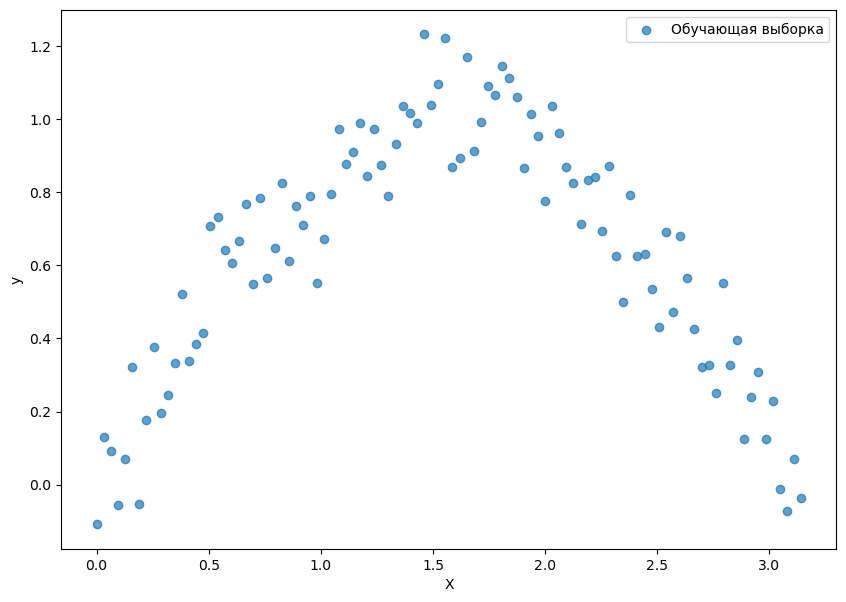

In [72]:
np.random.seed(123)
N = 100
X = np.linspace(0, 1*np.pi, N).reshape(-1, 1)
y = np.sin(X)[:, 0] + np.random.normal(0, 0.1, size = N)

# Функция для визуализации выборки и предсказаний
def plot_sample_model(X, y, plot_predictions=False, y_pred=None, y_pred_label=None, loss='mse'):
    plt.figure(figsize = (10, 7))
    plt.scatter(X, y, label = 'Обучающая выборка', alpha = 0.7)
    if plot_predictions:
        plt.plot(X, y_pred, label = y_pred_label, c = 'r')
        if loss == 'mse':
            plt.title('MSE: ' + str(mean_squared_error(y, y_pred)))
        elif loss == 'mae':
            plt.title('MAE: ' + str(mean_absolute_error(y, y_pred)))
    plt.xlabel('X')
    plt.ylabel('y')
    plt.legend();

plot_sample_model(X, y, plot_predictions = False)

**Шаг 0.** Имеем пустую композицию решающих деревьев $a(X) = \{\}$.

In [73]:
a = 0

**Шаг 1.** Обучим первое решающее дерево $DT_1$ и включим его в композицию: $a^{(1)}(X) = DT_1$. Получим предсказания композиции на обучающей выборке.

In [74]:
from sklearn.tree import DecisionTreeRegressor


In [75]:
# TODO: обучите решающее дерево глубины 1 и сделайте предсказания на обучающей выборке
dt = DecisionTreeRegressor(max_depth=1, random_state=122)
dt.fit(X, y)

y_pred = dt.predict(X)

In [76]:
# TODO: включите предсказания первого дерева в композицию (простым суммированием)
a = y_pred


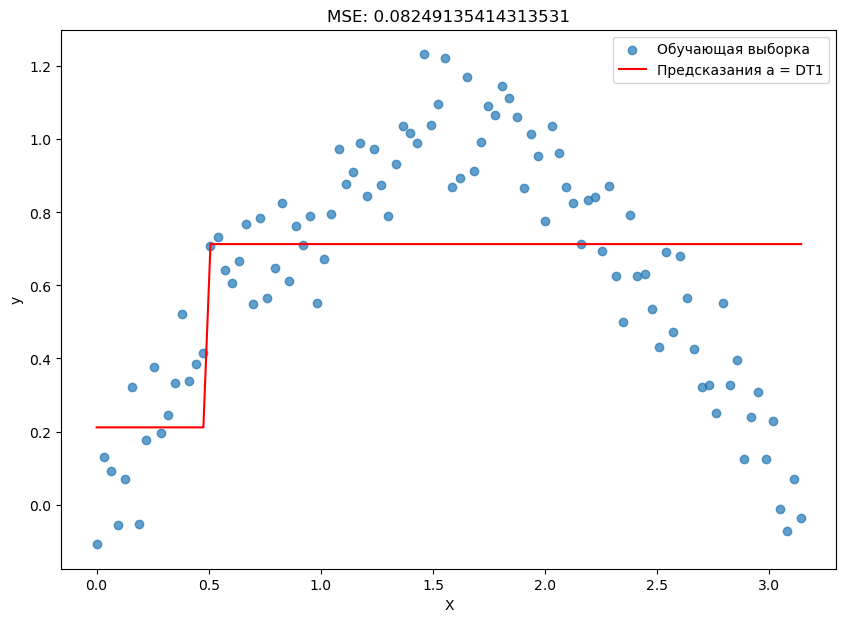

In [77]:
# Визуализация выборки и предсказаний
plot_sample_model(X, y, plot_predictions = True, y_pred = a, y_pred_label = 'Предсказания a = DT1')

**Шаг 2.** В качестве ошибок композиции будем использовать **сдвиги**, в случае MSE — это то же самое, что и остатки или ошибки


**Задание:** вычислите градиент $MSE$

$$
L(y, p) = \dfrac{1}{2} \sum_{i = 1}^{\ell} (y_i - p_i)^2
$$

по $p_i$ в точке $p_i = a(x_i)$.

Антиградиент функции потерь равен:

$$
s_i = y_i - a(x_i),
$$

In [78]:
# TODO: рассчитайте сдвиги
s1 = y - a

**Шаг 3.** Обучим второе решающее дерево $DT_2$, предсказывающее сдвиги. Добавим предсказания второго дерева в композицию: $a^{(2)}(X) = DT_1 + DT_2$. Получим предсказания композиции на обучающей выборке.

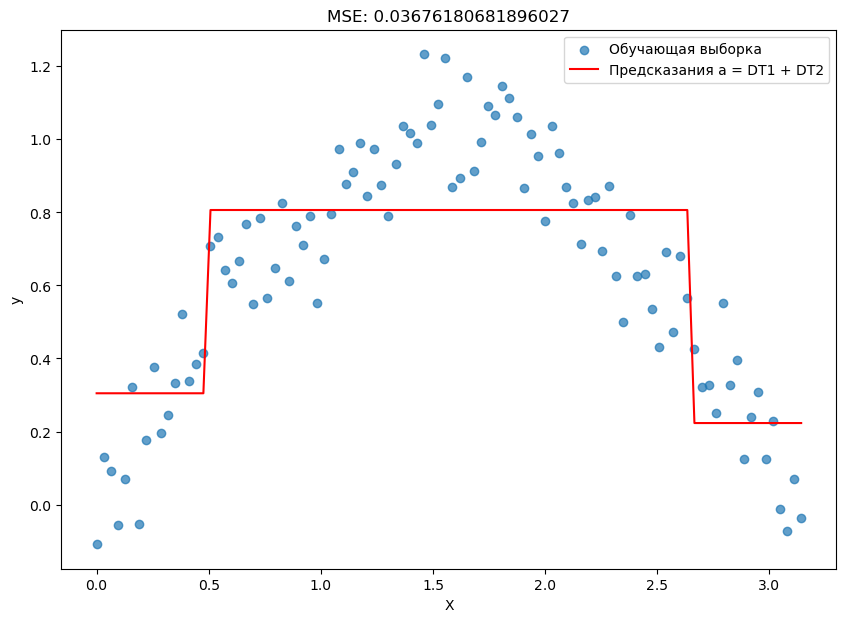

In [79]:
# TODO: обучите второе решающее дерево глубины 1, предсказывающее остатки
dt_2 = DecisionTreeRegressor(max_depth=1, random_state=124)
dt_2.fit(X, s1)

# TODO: сделайте предсказания на обучающей выборке
y_pred = dt_2.predict(X)
# TODO: включите предсказания второго дерева в композицию (простым суммированием)
a += y_pred

# Визуализация выборки и предсказаний
plot_sample_model(X, y, plot_predictions = True, y_pred = a, y_pred_label = 'Предсказания a = DT1 + DT2')

Как мы видим, решающая поверхность стала более сложной, и теперь она более точно приближает обучающую выборку.

**Шаги 4 – ...** Повторяем шаги 2-3, пока не надоест **:**

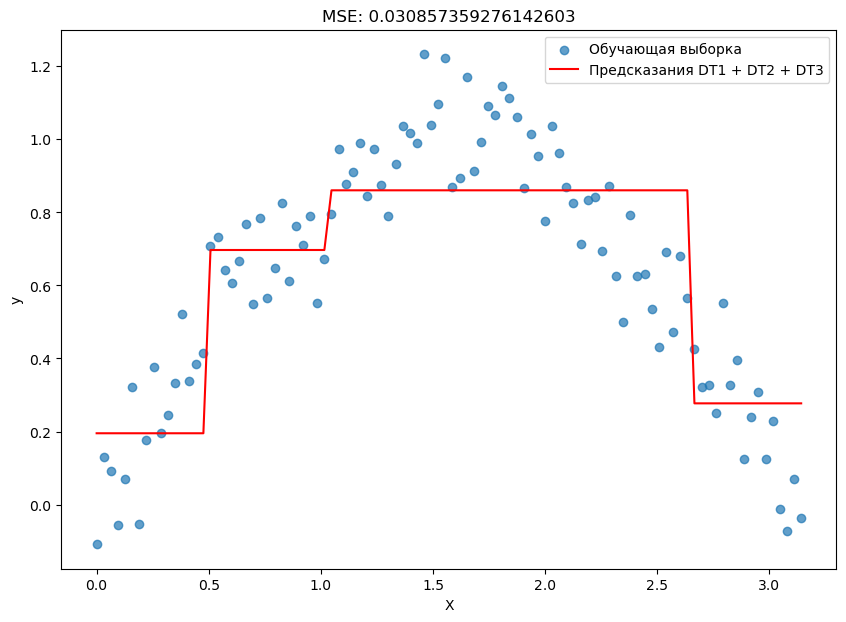

In [80]:
# TODO: рассчитайте остатки
s2 = y - a

# TODO: обучите третье решающее дерево глубины 1, предсказывающее остатки
dt_3 = DecisionTreeRegressor(max_depth=1, random_state=125)
dt_3.fit(X, s2)

# TODO: сделайте предсказания на обучающей выборке
y_pred = dt_3.predict(X)

# TODO: включите предсказания третьего дерева в композицию (простым суммированием)
a += y_pred

# Визуализация выборки и предсказаний
plot_sample_model(X, y, plot_predictions = True, y_pred = a, y_pred_label = 'Предсказания DT1 + DT2 + DT3')

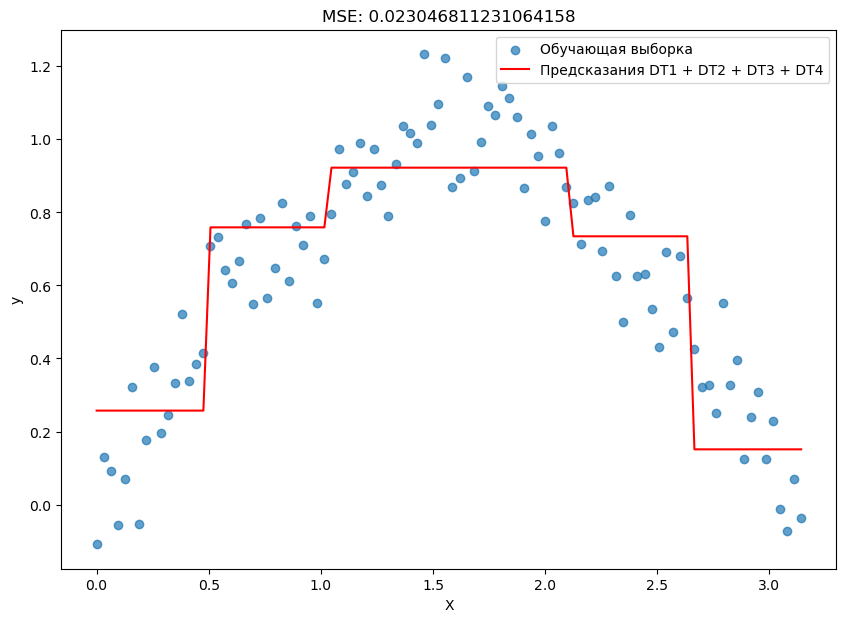

In [81]:
# TODO: рассчитайте остатки
s3 = y - a

dt_4 = DecisionTreeRegressor(max_depth=1, random_state=125)
dt_4.fit(X, s3)

# TODO: сделайте предсказания на обучающей выборке
y_pred = dt_4.predict(X)

# TODO: включите предсказания третьего дерева в композицию (простым суммированием)
a += y_pred

# Визуализация выборки и предсказаний
plot_sample_model(X, y, plot_predictions = True, y_pred = a, y_pred_label = 'Предсказания DT1 + DT2 + DT3 + DT4')

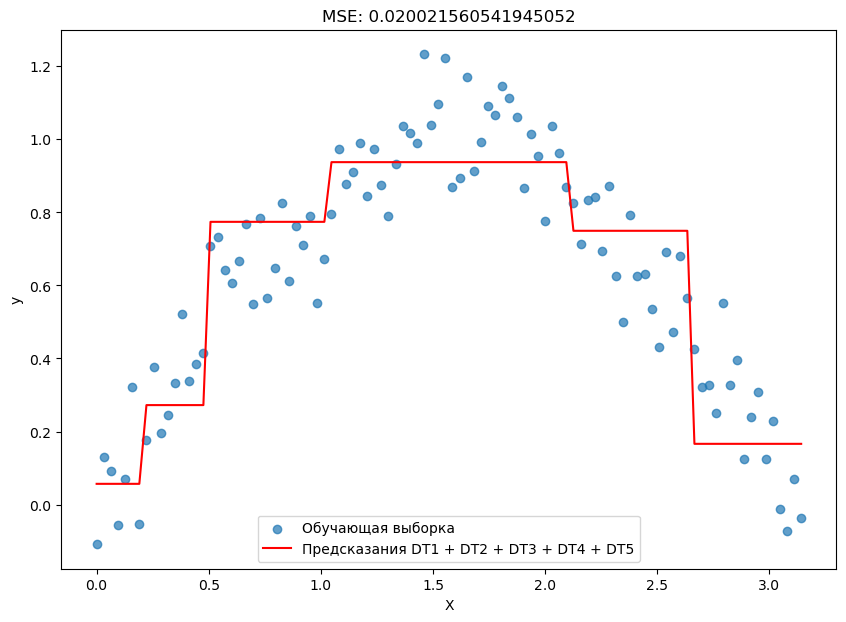

In [82]:
# TODO: рассчитайте остатки
s4 = y - a

# TODO: обучите третье решающее дерево глубины 1, предсказывающее остатки
dt_5 = DecisionTreeRegressor(max_depth=1, random_state=125)
dt_5.fit(X, s4)

# TODO: сделайте предсказания на обучающей выборке
y_pred = dt_5.predict(X)

# TODO: включите предсказания третьего дерева в композицию (простым суммированием)
a += y_pred

# Визуализация выборки и предсказаний
plot_sample_model(X, y, plot_predictions = True, y_pred = a, y_pred_label = 'Предсказания DT1 + DT2 + DT3 + DT4 + DT5')

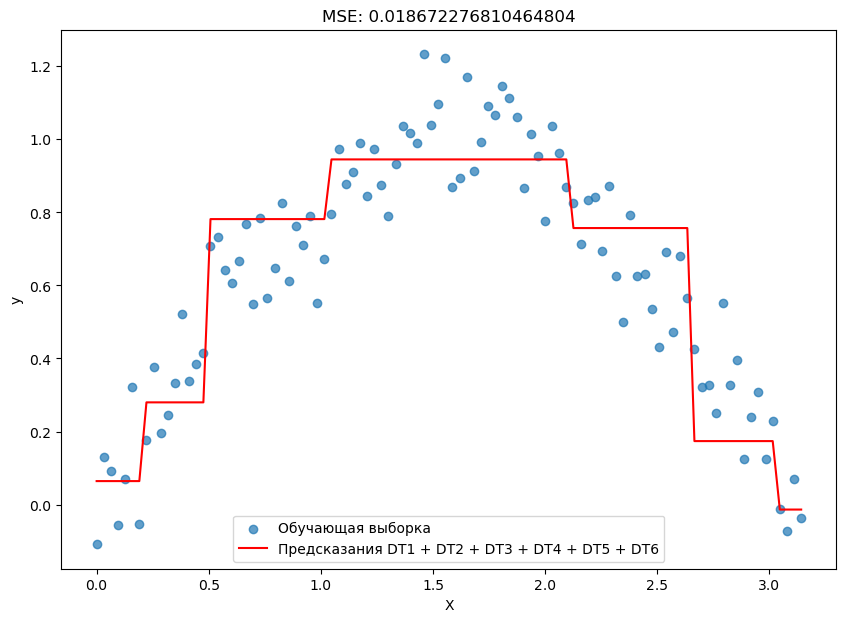

In [83]:
# TODO: рассчитайте остатки
s5 = y - a

# TODO: обучите третье решающее дерево глубины 1, предсказывающее остатки
dt_6 = DecisionTreeRegressor(max_depth=1, random_state=125)
dt_6.fit(X, s5)

# TODO: сделайте предсказания на обучающей выборке
y_pred = dt_6.predict(X)

# TODO: включите предсказания третьего дерева в композицию (простым суммированием)
a += y_pred

# Визуализация выборки и предсказаний
plot_sample_model(X, y, plot_predictions = True, y_pred = a, y_pred_label = 'Предсказания DT1 + DT2 + DT3 + DT4 + DT5 + DT6')

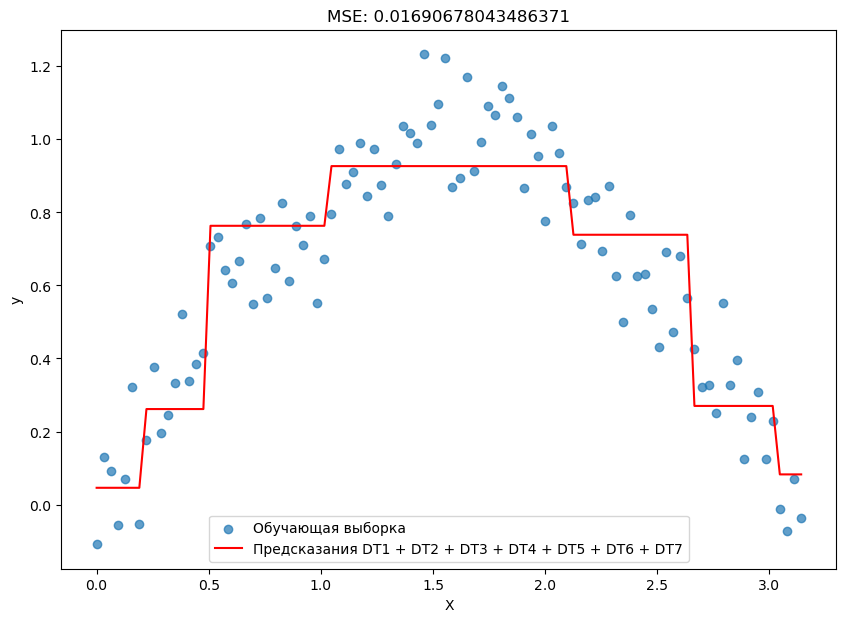

In [84]:
# TODO: рассчитайте остатки
s6 = y - a

# TODO: обучите третье решающее дерево глубины 1, предсказывающее остатки
dt_7 = DecisionTreeRegressor(max_depth=1, random_state=125)
dt_7.fit(X, s6)

# TODO: сделайте предсказания на обучающей выборке
y_pred = dt_7.predict(X)

# TODO: включите предсказания третьего дерева в композицию (простым суммированием)
a += y_pred

# Визуализация выборки и предсказаний
plot_sample_model(X, y, plot_predictions = True, y_pred = a, y_pred_label = 'Предсказания DT1 + DT2 + DT3 + DT4 + DT5 + DT6 + DT7')

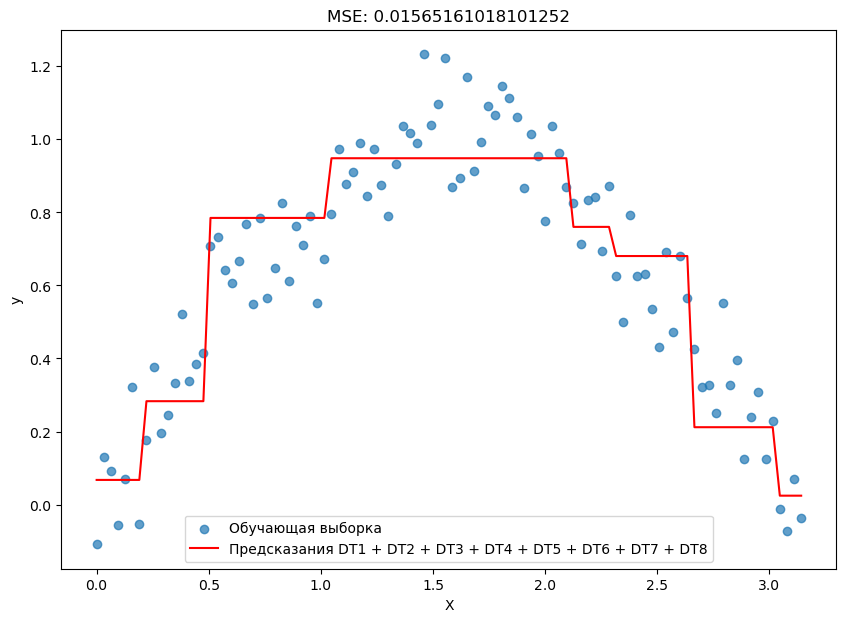

In [85]:
# TODO: рассчитайте остатки
s7 = y - a

# TODO: обучите третье решающее дерево глубины 1, предсказывающее остатки
dt_8 = DecisionTreeRegressor(max_depth=1, random_state=125)
dt_8.fit(X, s7)

# TODO: сделайте предсказания на обучающей выборке
y_pred = dt_8.predict(X)

# TODO: включите предсказания третьего дерева в композицию (простым суммированием)
a += y_pred

# Визуализация выборки и предсказаний
plot_sample_model(X, y, plot_predictions = True, y_pred = a, y_pred_label = 'Предсказания DT1 + DT2 + DT3 + DT4 + DT5 + DT6 + DT7 + DT8')

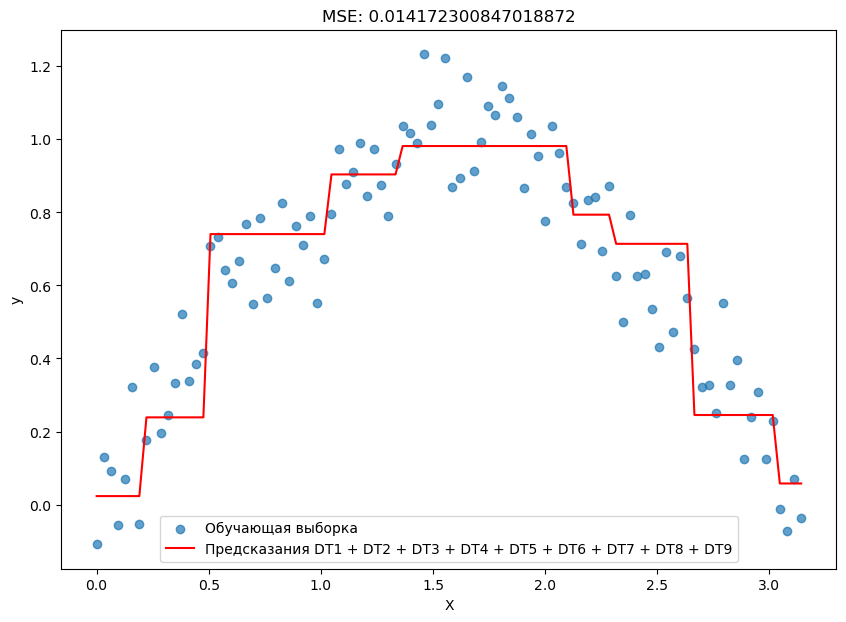

In [86]:
# TODO: рассчитайте остатки
s8 = y - a

# TODO: обучите третье решающее дерево глубины 1, предсказывающее остатки
dt_9 = DecisionTreeRegressor(max_depth=1, random_state=125)
dt_9.fit(X, s8)

# TODO: сделайте предсказания на обучающей выборке
y_pred = dt_9.predict(X)

# TODO: включите предсказания третьего дерева в композицию (простым суммированием)
a += y_pred

# Визуализация выборки и предсказаний
plot_sample_model(X, y, plot_predictions = True, y_pred = a, y_pred_label = 'Предсказания DT1 + DT2 + DT3 + DT4 + DT5 + DT6 + DT7 + DT8 + DT9')

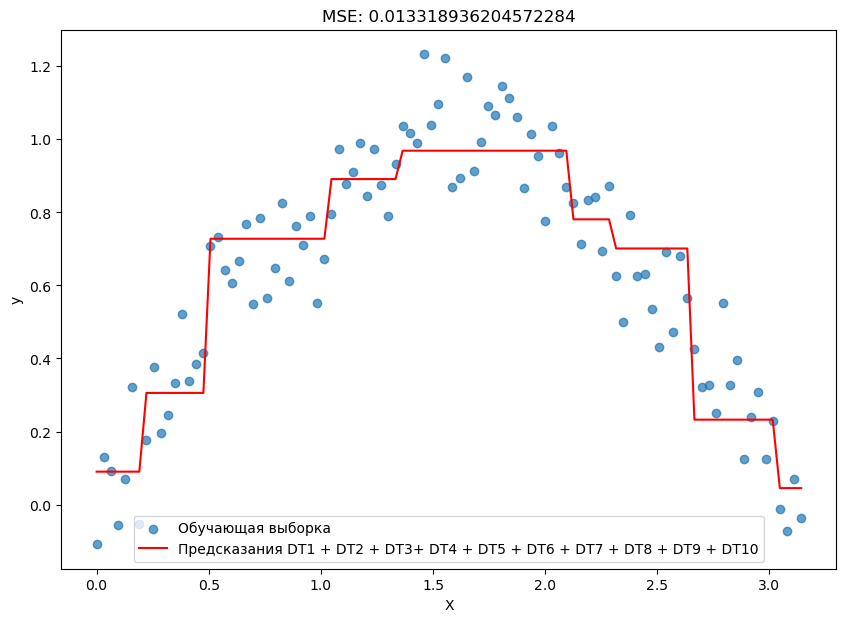

In [87]:
# TODO: рассчитайте остатки
s9 = y - a

# TODO: обучите третье решающее дерево глубины 1, предсказывающее остатки
dt_10 = DecisionTreeRegressor(max_depth=1, random_state=125)
dt_10.fit(X, s9)

# TODO: сделайте предсказания на обучающей выборке
y_pred = dt_10.predict(X)

# TODO: включите предсказания третьего дерева в композицию (простым суммированием)
a += y_pred

# Визуализация выборки и предсказаний
plot_sample_model(X, y, plot_predictions = True, y_pred = a, y_pred_label = 'Предсказания DT1 + DT2 + DT3+ DT4 + DT5 + DT6 + DT7 + DT8 + DT9 + DT10')

**Включаем s1 - остатки вместо y в модель, каждая последущая модель строится на основе остатков предыдущей**

**Всего моделей деревьев обучающихся на остатках, полученных после предыдущей модели, было построенно 10 , как можно заметить ошибка с каждой моделью становится все меньше и меньше**

Как мы видим, при добавлении базовых моделей решающая поверхность становится более сложной и всё точнее приближает обучающую выборку.

**Важный момент:** заметим, что при обучении очередной базовой модели композиция предыдущего шага считается фиксированной. Это означает, что обучение новой базовой модели не влияет на уже обученные модели, содержащиеся в композиции.

### 2. Функции потерь градиентного бустинга для регрессии и классификации

#### 2.1 Регрессия.

В задачах регрессии в качестве целевой функции для композиции обычно берутся:

1. $MSE$, которую мы рассматривали ранее.

2. $MAE$:

$$
MAE(y, p) = \sum_{i = 1}^{\ell} |y_i - p_i|
$$

Попробуем сделать шаг градиентного бустинга, используя в качестве функции потерь $MAE$.

**Задание:** рассчитайте $s_i$ для $MAE$.

**Решение:** $s_i^{(N)} = -\mathrm{sign}(a^{(N-1)}(x_i) - y_i)$.

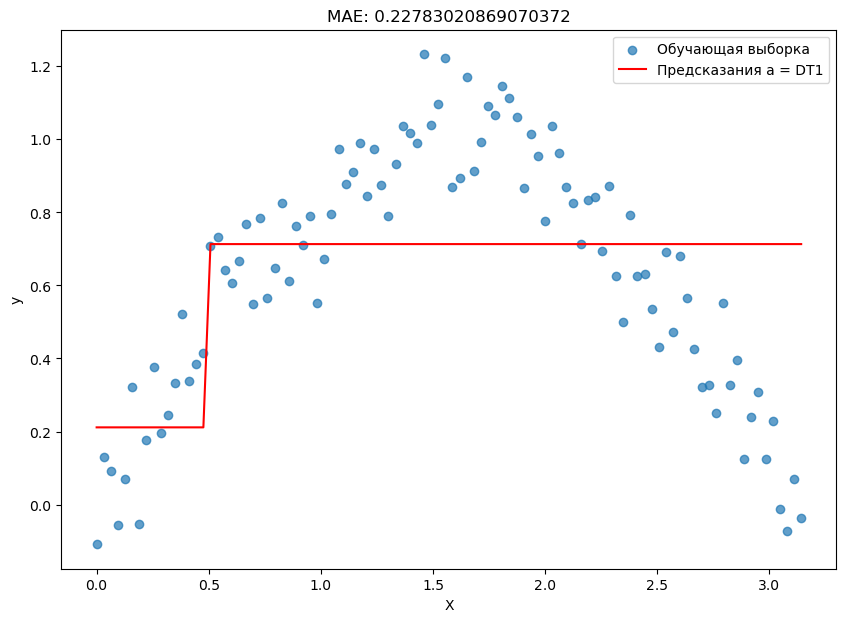

In [102]:
# Инициализация
a = 0

# Обучение решающего дерева глубины 1 и получение предсказаний на обучающей выборке
dt1 = DecisionTreeRegressor(max_depth = 1)
dt1.fit(X, y)
dt1_pred = dt1.predict(X)

# Включение предсказаний первого дерева в композицию (простым суммированием)
a = dt1_pred

# Визуализация выборки и предсказаний
plot_sample_model(X, y, plot_predictions = True, y_pred = a, y_pred_label = 'Предсказания a = DT1', loss = 'mae')

In [103]:
# TODO: рассчитайте антиградиент
s1 = -np.sign(a - y)

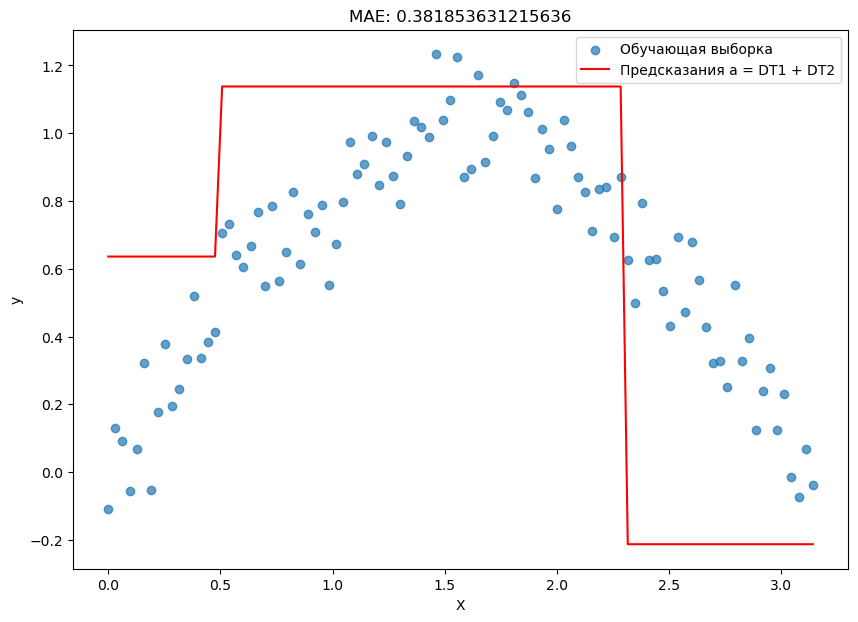

In [104]:
# Обучение второго решающего дерева глубины 1, предсказывающего антиградиент
dt2 = DecisionTreeRegressor(max_depth = 1)
dt2.fit(X, s1)

# Получение предсказаний на обучающей выборке
dt2_pred = dt2.predict(X)

# Включение предсказаний второго дерева в композицию (простым суммированием)
a += dt2_pred

# Визуализация выборки и предсказаний
plot_sample_model(X, y, plot_predictions = True, y_pred = a,
                  y_pred_label = 'Предсказания a = DT1 + DT2', loss = 'mae')

Заметим, что $MAE$ увеличилась, а решающая поверхность имеет "виток", уходящий за пределы обучающей выборки.

#### 2.2 Классификация.

В задачах бинарной классификации обычно используется логистическая функция потерь, с которой мы уже сталкивались в логистической регрессии.

$$
L(y, p) = \log(1 + e^{-yp}).
$$

В этом случае антиградиенты можно вычислить по формуле

$$
s^{(N)}_i = \dfrac{y_i}{1 + e^{y_ia^{(N-1)}(x_i)}}
$$

Попробуем сделать шаг градиентного бустинга в задаче бинарной классификации с логистической функцией потерь.

In [254]:
from sklearn.datasets import make_moons, load_iris # import function from the library

N = 1000

X, y = make_moons(n_samples=N, noise=0.1, random_state=11) # generate data sample
y = y * 2 - 1 # {-1, +1}

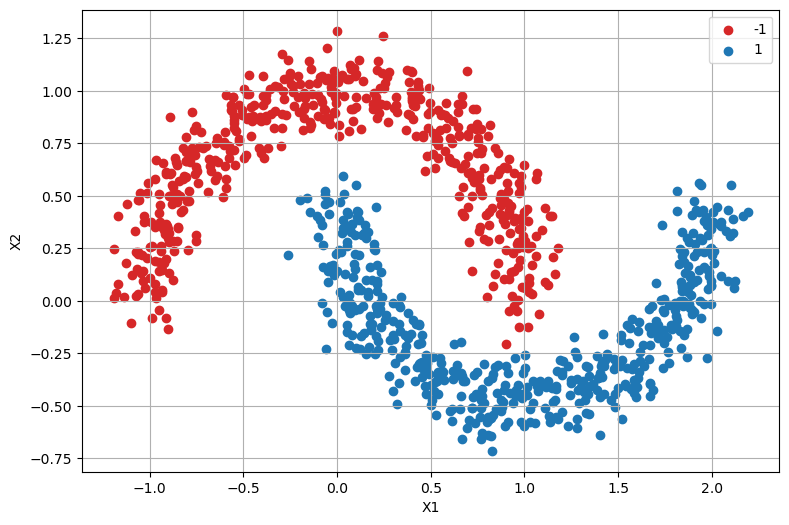

In [255]:
# Create an figure with a custom size
plt.figure(figsize=(9, 6))

# Plot all objects with y == 0 (class 0)
plt.scatter(X[y == -1, 0],     # selects all objects with y == 0 and the 1st column of X
            X[y == -1, 1],     # selects all objects with y == 0 and the 2nd column of X
            color='C3',        # points color
            label='-1')        # label for the plot legend


# Plot all objects with y == 1 (class 1)
plt.scatter(X[y == 1, 0],     # selects all objects with y == 1 and the 1st column of X
            X[y == 1, 1],     # selects all objects with y == 1 and the 2nd column of X
            color='C0',        # points color
            label='1')        # label for the plot legend

plt.xlabel('X1') # set up X-axis label
plt.ylabel('X2') # set up Y-axis label

plt.legend(loc='best') # create the plot legend and set up it position
plt.grid() # create grid on the plot

plt.show() # display the plot


In [256]:
# Инициализация
a = 0

# Обучение решающего дерева глубины 1 и получение предсказаний на обучающей выборке
dt1 = DecisionTreeRegressor(max_depth = 1)
dt1.fit(X, y)
dt1_pred = dt1.predict(X)

# Включение предсказаний первого дерева в композицию (простым суммированием)
a = dt1_pred

In [257]:
def log_loss(y, y_pred):
    return np.log(1 + np.exp(- y * y_pred)).mean()

In [258]:
from sklearn.metrics import roc_auc_score

# Вычисление ошибки для одного дерева
ll = log_loss(y, a)
print("LogLoss = %f" % (ll))

# Вычисление ROC AUC
auc = roc_auc_score(y, a)
print("ROC AUC = %f" % (auc))

LogLoss = 0.507347
ROC AUC = 0.839000


In [259]:
# TODO: рассчитайте антиградиент
s1 = y / (1 + np.exp(y * a))

In [260]:
# Обучение второго решающего дерева глубины 1, предсказывающего антиградиент
dt2 = DecisionTreeRegressor(max_depth = 1)
dt2.fit(X, s1)

# Получение предсказаний на обучающей выборке
dt2_pred = dt2.predict(X)

In [261]:
# Включение предсказаний второго дерева в композицию (простым суммированием)
a += dt2_pred

In [262]:
# Вычисление ошибки для одного дерева
ll = log_loss(y, a)
print("LogLoss = %f" % (ll))

LogLoss = 0.451541


In [263]:
# Вычисление ROC AUC
auc = roc_auc_score(y, a)
print("ROC AUC = %f" % (auc))

ROC AUC = 0.926192



При получении новой модели с учетом антиградиента, то есть построении новой модели и ее обучении на основе антиградиента, метрики оценки показали лучшие результаты. Метрика LogLoss уменьщилась с 0,51 до 0,45, а метрика ROC AUC увеличилась с 0,84 до 0.93, это говорит о том, что модель улучшилась, а также стала разделять (бинарные) классы лучше.


Наилучшее значение ROC AUC = 1

Наилучшее значение LogLoss = 0

### 3. Особенности градиентного бустинга

#### 3.1 Построение композиции.

В примерах выше мы строили композицию моделей простым суммированием. Понятно, что в общем виде можно строить взвешенную сумму базовых моделей:

$$
a(X) = \sum_{n = 1}^{k} w_nb_n(X),
$$

где коэффициенты $w_n$ можно подобрать, например, при помощи градиентного спуска в задаче

$$
w_n = \arg\min_{w} \sum_{i = 1}^{\ell} L(y_i, a^{(N-1)}(x_i) + w \times b_N(x_i)),
$$

что имеет смысл, так как $b_N(x_i)$ уже обучена и фиксирована.

**Замечание:** длина шага является одним из ключевых параметров градиентного бустинга, и может очень сильно повлиять на результат.

В нашем случае подбор правильного коэффициента поможет решить увеличение MAE в примере 3.1.

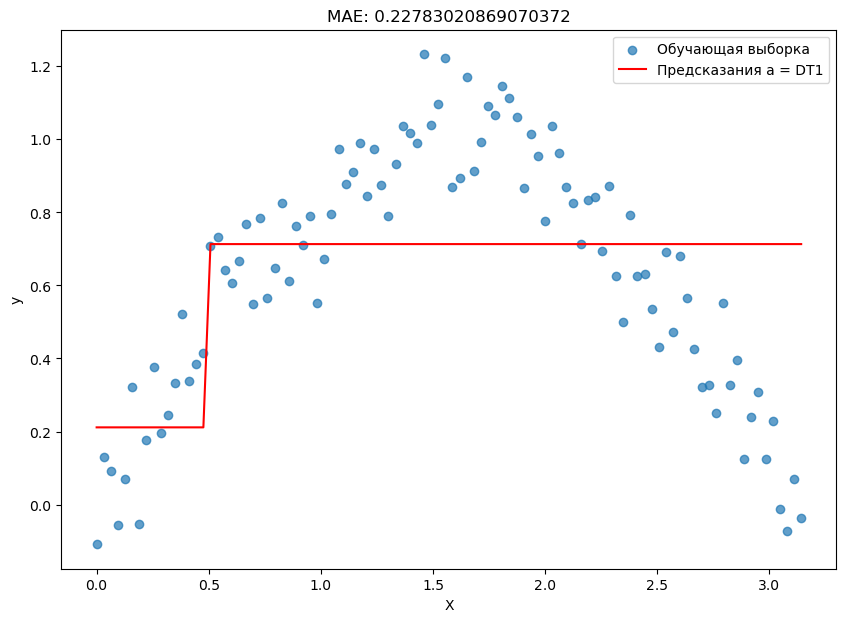

In [159]:
# Инициализация
np.random.seed(123)
N = 100
X = np.linspace(0, 1*np.pi, N).reshape(-1, 1)
y = np.sin(X)[:, 0] + np.random.normal(0, 0.1, size = N)
a = 0

# Обучение решающего дерева глубины 1 и получение предсказаний на обучающей выборке
dt1 = DecisionTreeRegressor(max_depth = 1)
dt1.fit(X, y)
dt1_pred = dt1.predict(X)

# Включение предсказаний первого дерева в композицию (простым суммированием)
a = dt1_pred

# Визуализация выборки и предсказаний
plot_sample_model(X, y, plot_predictions = True, y_pred = a, y_pred_label = 'Предсказания a = DT1', loss = 'mae')

In [160]:
# Вычисление антиградиента
s1 = -np.sign(a - y)

In [161]:
# TODO: подберите (угадайте) вес так, чтобы уменьшить MAE
w = 0.3

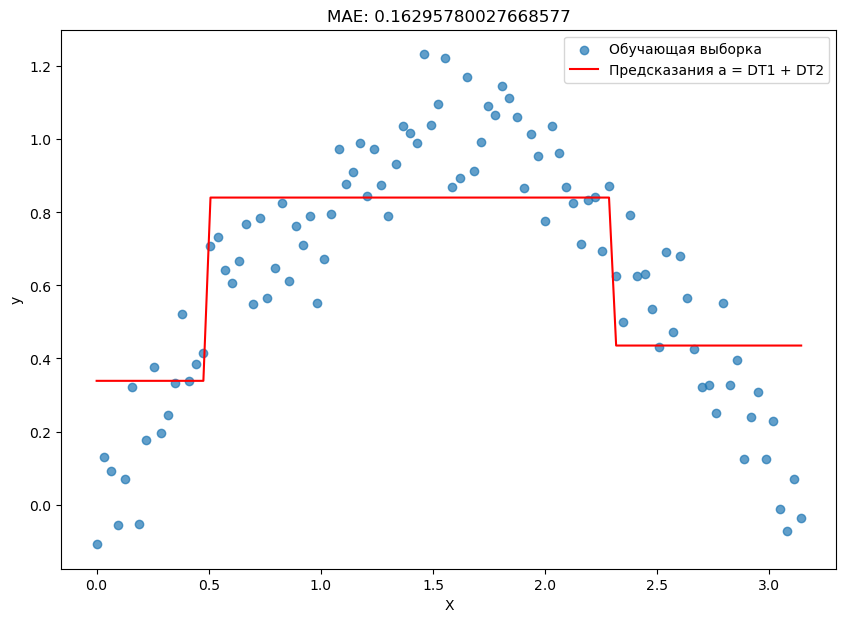

In [162]:
# Обучение второго решающего дерева глубины 1, предсказывающего антиградиент
dt2 = DecisionTreeRegressor(max_depth = 1)
dt2.fit(X, s1)

# Получение предсказаний на обучающей выборке
dt2_pred = dt2.predict(X)

# Включение предсказаний второго дерева в композицию (простым суммированием)
a += w * dt2_pred

# Визуализация выборки и предсказаний
plot_sample_model(X, y, plot_predictions = True, y_pred = a,
                  y_pred_label = 'Предсказания a = DT1 + DT2', loss = 'mae')

**Мы получили ошибку MAE меньше чем при построение первой модели, что говорит о том, что выбранный параметр веса (w),был подобран правильно**

#### 3.2 Переобучение.

В контексте метода бэггинга, увеличение количества базовых моделей не приводит к переобучению. В частности, при использовании случайного леса, можно наблюдать, что ошибки на тренировочной и тестовой выборках достигают плато после достижения определенного числа деревьев. В отличие от бэггинга, бустинг по своей конструкции не обладает таким свойством: при добавлении новых базовых моделей композиция всё более точно аппроксимирует обучающую выборку, что может привести к переобучению, зачастую достаточно быстро. 

Следовательно, можно заключить, что в случае бустинга ошибка на обучающей выборке в зависимости от числа деревьев является монотонно убывающей функцией, тогда как ошибка на тестовой выборке, вероятно, будет иметь U-образную форму. 

Для подтверждения этих выводов следует провести сравнительный анализ поведения ошибок и решающих поверхностей бустинга и случайного леса.

Здесь и далее будем использовать [реализацию бустинга](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingRegressor.html) из `sklearn`, которая представляет собой градиентный бустинг над деревьями.

In [163]:
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor

In [164]:
# Генерация выборки
np.random.seed(123)
X = np.linspace(0, 1, 300).reshape(-1, 1)

def target(a):
    return a > 0.5

y = target(X) + np.random.normal(size = X.shape) * 0.1
y = y[:, 0]

In [165]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3)

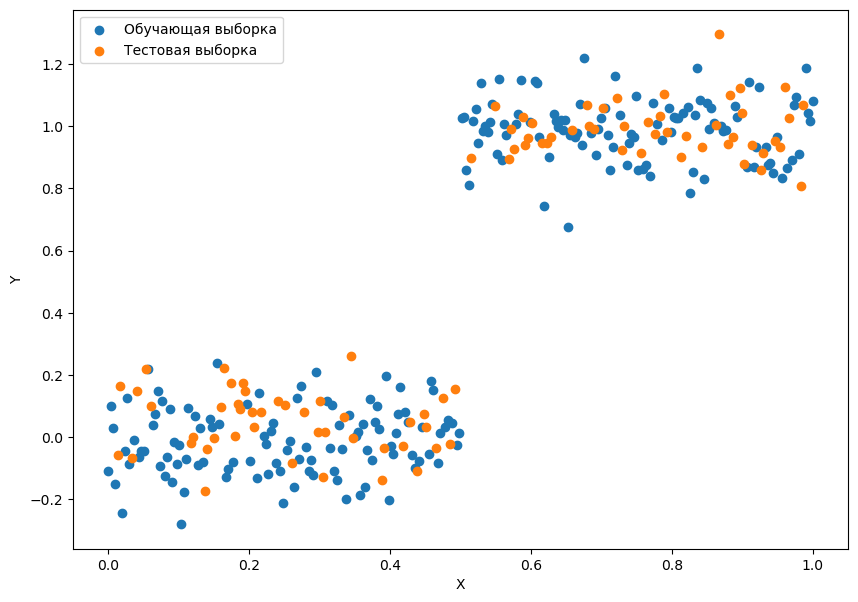

In [166]:
# Визуализация выборки
plt.figure(figsize = (10, 7))
plt.scatter(X_train, y_train, label = 'Обучающая выборка')
plt.scatter(X_test, y_test, label = 'Тестовая выборка')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend();

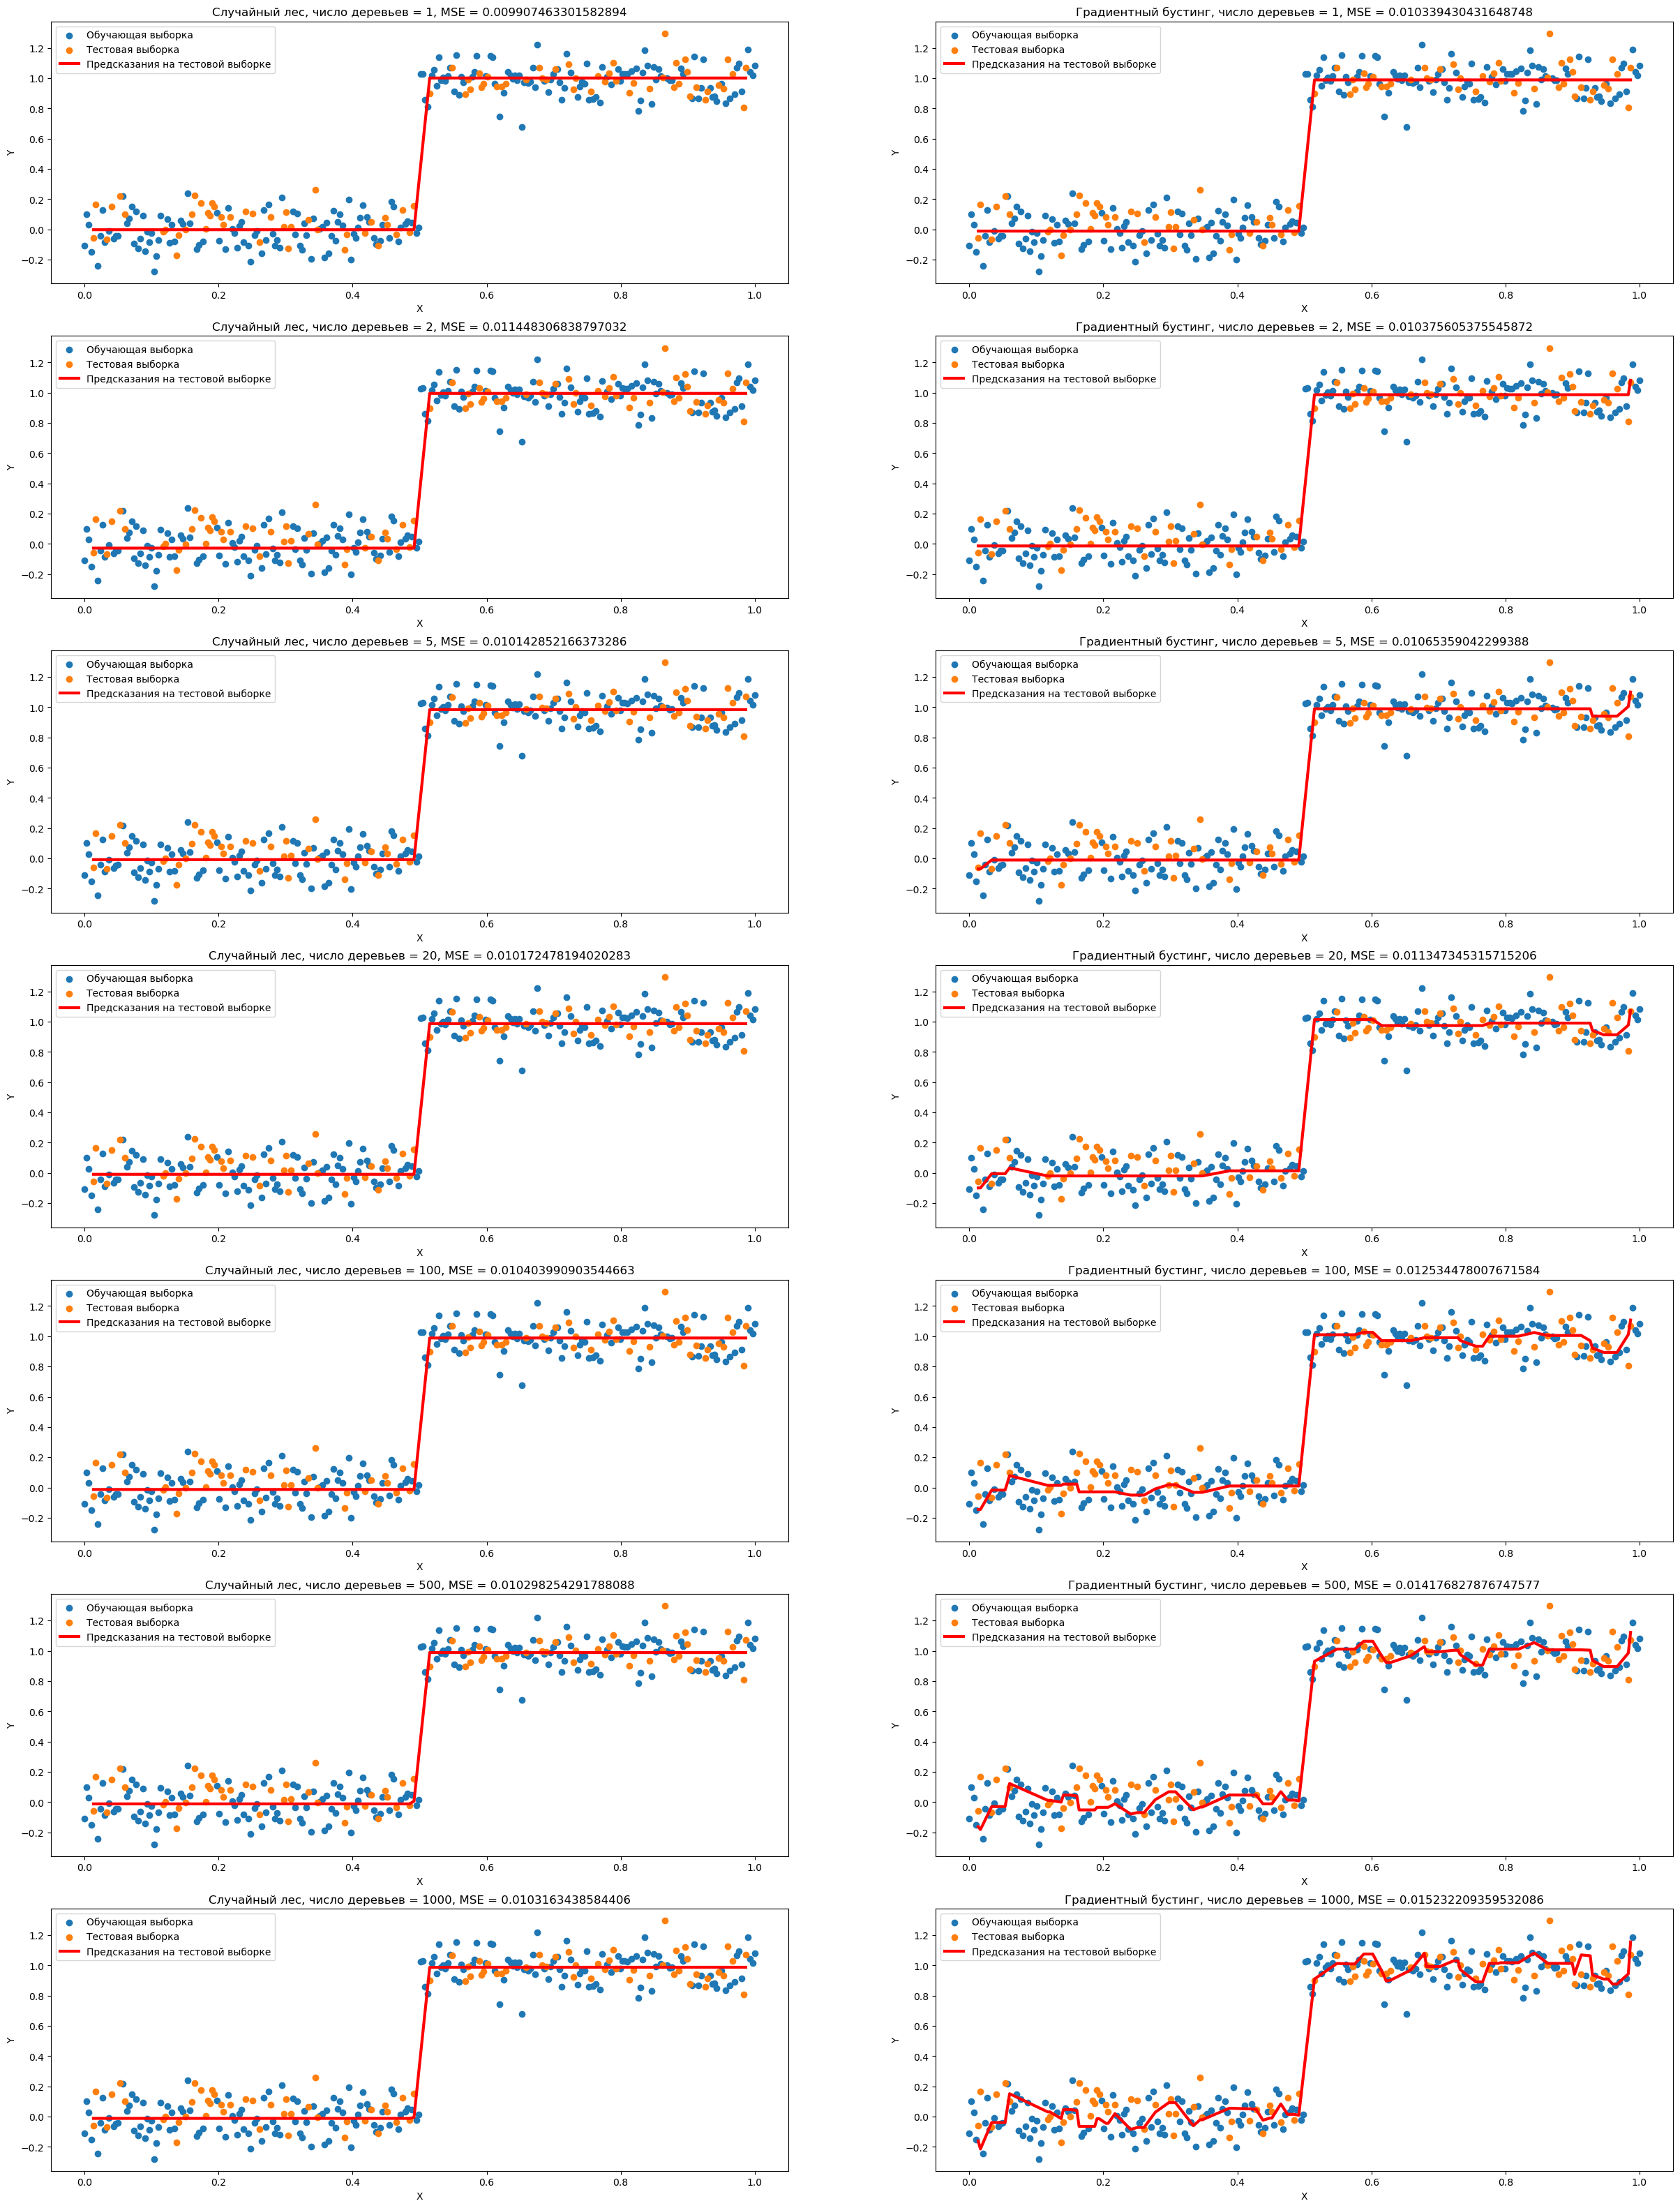

In [167]:
# Визуализация решающих поверхностей
trees = [1, 2, 5, 20, 100, 500, 1000]

fig, ax = plt.subplots(len(trees), 2, figsize = (30, 40))

loss_rf_train = []
loss_gb_train = []
loss_rf_test = []
loss_gb_test = []

for i, ts in enumerate(trees):
    rf = RandomForestRegressor(n_estimators = ts, max_depth = 1)
    gb = GradientBoostingRegressor(n_estimators = ts, max_depth = 1, learning_rate = 1)

    rf.fit(X_train, y_train)
    ax[i, 0].scatter(X_train, y_train, label = 'Обучающая выборка')
    ax[i, 0].scatter(X_test, y_test, label = 'Тестовая выборка')
    ax[i, 0].plot(sorted(X_test), rf.predict(sorted(X_test)), lw = 3, c = 'red', label = 'Предсказания на тестовой выборке')
    ax[i, 0].set_xlabel('X')
    ax[i, 0].set_ylabel('Y')
    ax[i, 0].set_title('Случайный лес, число деревьев = ' + str(ts) + ', MSE = ' + str(mean_squared_error(y_test, rf.predict(X_test))))
    ax[i, 0].legend();

    loss_rf_train.append(mean_squared_error(y_train, rf.predict(X_train)))
    loss_rf_test.append(mean_squared_error(y_test, rf.predict(X_test)))

    gb.fit(X_train, y_train)
    ax[i, 1].scatter(X_train, y_train, label = 'Обучающая выборка')
    ax[i, 1].scatter(X_test, y_test, label = 'Тестовая выборка')
    ax[i, 1].plot(sorted(X_test), gb.predict(sorted(X_test)), lw = 3, c = 'red', label = 'Предсказания на тестовой выборке')
    ax[i, 1].set_xlabel('X')
    ax[i, 1].set_ylabel('Y')
    ax[i, 1].set_title('Градиентный бустинг, число деревьев = ' + str(ts) + ', MSE = ' + str(mean_squared_error(y_test, gb.predict(X_test))))
    ax[i, 1].legend();

    loss_gb_train.append(mean_squared_error(y_train, gb.predict(X_train)))
    loss_gb_test.append(mean_squared_error(y_test, gb.predict(X_test)))

Как мы видим, решающая поверхность случайного леса не изменяется (уже со второго дерева), в то время как для бустинга она становится всё более сложной.

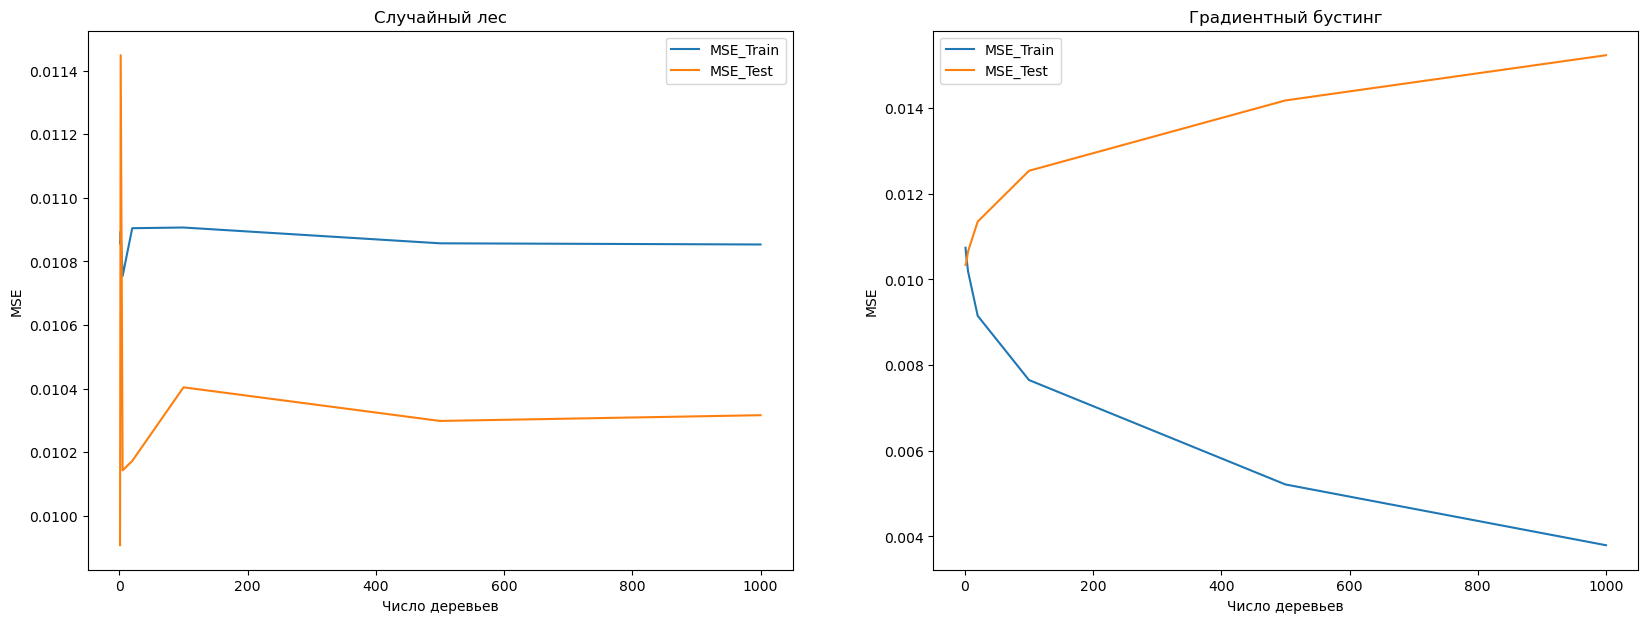

In [168]:
# Визуализация ошибок
fig, ax = plt.subplots(1, 2, figsize = (20, 7))

ax[0].plot(trees, loss_rf_train, label = 'MSE_Train')
ax[0].plot(trees, loss_rf_test, label = 'MSE_Test')
ax[0].set_xlabel('Число деревьев')
ax[0].set_ylabel('MSE')
ax[0].set_title('Случайный лес')
ax[0].legend()

ax[1].plot(trees, loss_gb_train, label = 'MSE_Train')
ax[1].plot(trees, loss_gb_test, label = 'MSE_Test')
ax[1].set_xlabel('Число деревьев')
ax[1].set_ylabel('MSE')
ax[1].set_title('Градиентный бустинг')
ax[1].legend();

В случае бустинга ошибка на тренировочной выборке стабильно убывает, а на тестовой – возрастает, что вероятно говорит об (очень быстром) переобучении. Если же мы аккуратно подберём гиперпараметры для деревьев и длину шага, то сможем добиться типичной U-образной формы функции потерь на тестовой выборке.

В качестве способа регуляризации также может использоваться сокращение шага:

$$
a^{(N)}(X) = a^{(N-1)}(X) + \alpha w_N b^{(N)}(X),
$$

где $\alpha \in (0, 1]$ – темп обучения, или стохастический градиентный бустинг.

**Важный момент:** примеры выше демонстрируют, насколько быстро бустинг может переобучаться, и как в его случае важен подбор гиперпараметров. В связи с этим может сложиться ситуация, что градиентный бустинг с дефолтными параметрами показывает более плохое качество, чем, например, случайный лес с дефолтными параметрами, однако хорошо настроенный градиентный бустинг [обычно превосходит](https://www.quora.com/How-can-the-performance-of-a-Gradient-Boosting-Machine-be-worse-than-Random-Forests) случайный лес по качеству.

### 4. Catboost vs. XGBoost vs. LightGBM

In [169]:
!pip install catboost lightgbm cmake xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.9/28.9 MB 60.6 MB/s  0:00:00 eta 0:00:01


Ранее мы смотрели простую версию градиентного бустинга из scikit-learn, [придуманную в 1999 году Фридманом](https://projecteuclid.org/download/pdf_1/euclid.aos/1013203451). 

На сегодняшний день есть три популярные библиотеки с разными имплементациями градиентного бустинга, которые на практике показывают лушие результаты:
*  **XGBoost**. Появилась в 2014 году, [статья автора](https://arxiv.org/pdf/1603.02754.pdf) вышла в 2016. После выхода быстро набрала популярность и оставалась стандартом до конца 2016 года.
* **CatBoost** от компании Яндекс с релизом в 2017 году. Алгоритм можно запускать с дефолтными гиперпараметрами, потому тчо он является менее чувствительным к выбору их конкретных значений. Отлично умеет работать с категориальным признаками, при этом автоматически обрабатывая полученные на вход непредобработанные фичи.
* **LightGBM**. Релиз в один год с Catboost, библиотека от Microsoft. Отличается очень быстрым построением композиции. Например, при построении узла дерева, вместо перебора по всем значениям признака, производится перебор значений гистограммы этого признака. Таким образом, вместо $O(N)$ требуется $O$(m), где $m$ - число бинов гистограммы. В отличие от других библиотек, строит деревья в глубину, при этом на каждом шаге строит вершину, дающую наибольшее уменьшение функционала.

In [ ]:
#!pip install catboost lightgbm cmake xgboost # без cmake xgboost установится, но не будет импортироваться
#!pip install catboost

In [170]:
import catboost
import lightgbm
import xgboost

In [171]:
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import make_classification
from matplotlib.colors import ListedColormap
%matplotlib inline

plt.rcParams["figure.figsize"] = (8, 5)

#### 4.1 Catboost

Особенности Catboost:

1. Симметричные деревья решений

2. Для кодирования категориальных признаков используется большой набор методов

3. Динамический бустинг (данные, на которых были допущены ошибки, получают больший вес)

Симметричное (symmetric) дерево решений:

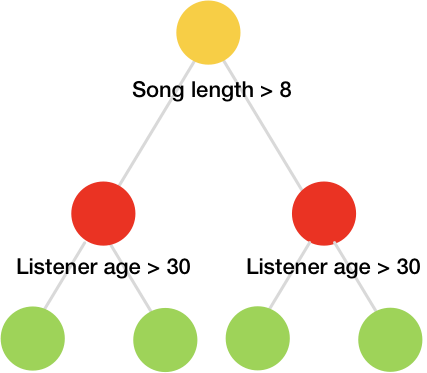

В алгоритме сделаны улучшения и выбор разных опций для борьбы с переобучением, подсчету среднего таргета на отложенной выборке, подсчету статистик по категориальным фичам, бинаризацией фичей, рандомизации скора сплита, разные типы бутсрапирования.

Сначала зафиксируем все гиперпараметры со значениями по умолчанию, кроме количества деревьев в композиции - `n_estimators`.

In [172]:
def plot_surface(X, y, clf):
    h = 0.2
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])

    Z = Z.reshape(xx.shape)
    cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
    plt.pcolormesh(xx, yy, Z, cmap=cmap_light)

    # Добавим на график сами наблюдения
    cmap_bold = ListedColormap(['#FF0000', '#00FF00', '#0000FF'])
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap_bold)
    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())

X, y = make_classification(n_samples=500, n_features=2, n_informative=2,
                           n_redundant=0, n_repeated=0,
                           n_classes=2, n_clusters_per_class=2,
                           flip_y=0.05, class_sep=0.8, random_state=241)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=241)

0.919452347083926


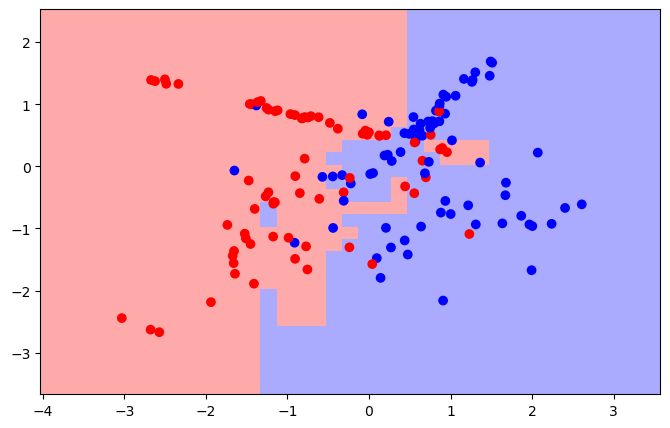

In [173]:
from catboost import CatBoostClassifier

catboost = CatBoostClassifier(n_estimators=300,
                              logging_level='Silent'
                              # можно подать список тех признаков, с которыми надо работать, как с категориальным
                              #cat_features = ...
                              )
catboost.fit(X_train, y_train)
plot_surface(X_test, y_test, catboost)

print(roc_auc_score(y_test, catboost.predict_proba(X_test)[:, 1]))

#### 4.2 XGBoost

Особенности XGBoost:


1. Базовый алгоритм приближает направление, посчитанное с учетом второй производной функции потерь

2. Функционал регуляризуется – добавляются штрафы за количество листьев и за норму коэффициентов

3. При построении дерева используется критерий информативности, зависящий от оптимального вектора сдвига

4. Критерий останова при обучении дерева также зависит от оптимального сдвига



0.8797119487908962


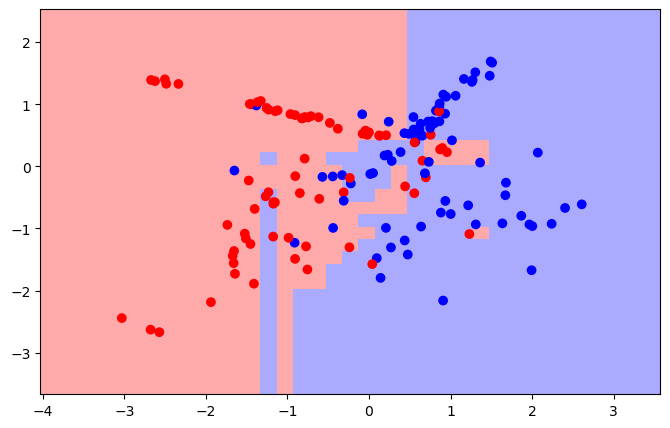

In [174]:
from xgboost import XGBClassifier

xgb = XGBClassifier(n_estimators=300, verbosity=0)
xgb.fit(X_train, y_train)
plot_surface(X_test, y_test, xgb)

print(roc_auc_score(y_test, xgb.predict_proba(X_test)[:, 1]))

#### 4.3 LightGBM

Особенности LightGBM:

1.   Полиственное (leaf-wise), а не поуровневое (depth-wise) построение деревьев; Про отличие написано [здесь](https://datascience.stackexchange.com/questions/26699/decision-trees-leaf-wise-best-first-and-level-wise-tree-traverse)
2. Бинаризация числовых признаков (объединение значений признака в группы, как при создании гистограммы)
3. Работа с изначальными категориальными признаками: оптимальный сплит для категориального признака ищется разделением множества категорий на 2 группы (существует эффективный способ поиска оптимального разбиения)

Итого: быстрее и требует меньше памяти



[LightGBM] [Info] Number of positive: 172, number of negative: 178
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000182 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 235
[LightGBM] [Info] Number of data points in the train set: 350, number of used features: 2
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.491429 -> initscore=-0.034289
[LightGBM] [Info] Start training from score -0.034289
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best 

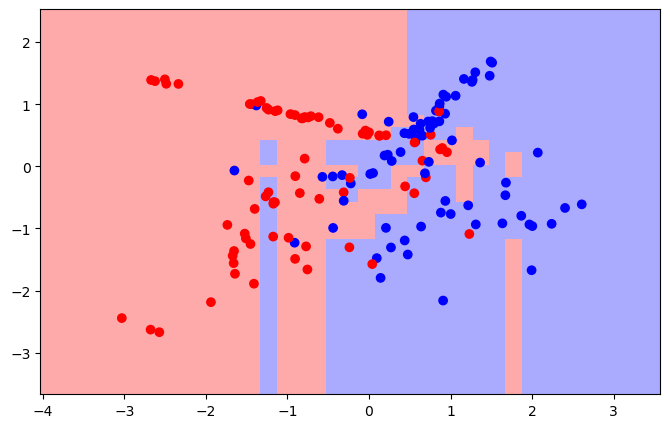

In [175]:
from lightgbm import LGBMClassifier

lightgbm = LGBMClassifier(n_estimators=300)
lightgbm.fit(X_train, y_train)
plot_surface(X_test, y_test, lightgbm)

print(roc_auc_score(y_test, lightgbm.predict_proba(X_test)[:, 1]))

Когда мы обучили лучшие версии моделей, можно их сохранить и использовать для получения предсказаний, например, на новом батче данных.

In [ ]:
'''
# Сохранить
lightgbm.booster_.save_model('lightgbm.txt')
catboost.save_model('catboost.cbm', format='cbm')
xgboost.save_model('xgboost.json')

# Загрузить
lightgbm = LGBMClassifier(model_file='mode.txt')
catboost = catboost.load_model('catboost.cbm')
xgboost = xgboost.load_model('xgboost.json')
''';

## 5. Тестирование градиентного бустинга (Задание)

Проведите серию экспериментов, используя различные модели (градиентного бустинга) и метрики оценки качества, чтобы получить более полное представление о поведении алгоритма. Кроме того, целесообразно выполнить подбор гиперпараметров градиентного бустинга с целью достижения определенного порога качества, что позволит оценить потенциал данного алгоритма в конкретном контексте.

Набор данных Грибы (бинарная классификация). Этот набор данных был очищен с помощью различных методов, таких как модальная импутация, одноточечное кодирование, нормализация z-score и выбор признаков. Он содержит 9 столбцов:

- Диаметр колпачка
- Форма колпачка
- Прикрепление жабр
- Цвет жаберной крышки
- Высота стебля
- Ширина стебля
- Цвет стебля
- Сезон
- Целевой класс - съедобный или нет?

Целевой класс содержит два значения - 0 или 1, где 0 означает съедобность, а 1 - ядовитость.


In [274]:
df = pd.read_csv('mushroom_cleaned (1).csv')

In [275]:
df

,cap-diameter,cap-shape,gill-attachment,gill-color,stem-height,stem-width,stem-color,season,class
0,1372,2,2,10,3.807467,1545,11,1.804273,1
1,1461,2,2,10,3.807467,1557,11,1.804273,1
2,1371,2,2,10,3.612496,1566,11,1.804273,1
3,1261,6,2,10,3.787572,1566,11,1.804273,1
4,1305,6,2,10,3.711971,1464,11,0.943195,1
...,...,...,...,...,...,...,...,...,...
54030,73,5,3,2,0.887740,569,12,0.943195,1
54031,82,2,3,2,1.186164,490,12,0.943195,1
54032,82,5,3,2,0.915593,584,12,0.888450,1
54033,79,2,3,2,1.034963,491,12,0.888450,1


In [276]:
X = df.drop('class', axis=1)
y = df['class']

In [277]:
X

,cap-diameter,cap-shape,gill-attachment,gill-color,stem-height,stem-width,stem-color,season
0,1372,2,2,10,3.807467,1545,11,1.804273
1,1461,2,2,10,3.807467,1557,11,1.804273
2,1371,2,2,10,3.612496,1566,11,1.804273
3,1261,6,2,10,3.787572,1566,11,1.804273
4,1305,6,2,10,3.711971,1464,11,0.943195
...,...,...,...,...,...,...,...,...
54030,73,5,3,2,0.887740,569,12,0.943195
54031,82,2,3,2,1.186164,490,12,0.943195
54032,82,5,3,2,0.915593,584,12,0.888450
54033,79,2,3,2,1.034963,491,12,0.888450


In [278]:
y

0        1
1        1
2        1
3        1
4        1
        ..
54030    1
54031    1
54032    1
54033    1
54034    1
Name: class, Length: 54035, dtype: int64

In [279]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=17)

#### 4.1 Catboost

In [286]:
from sklearn.metrics import accuracy_score

In [287]:
from sklearn.model_selection import GridSearchCV

In [304]:
from catboost import CatBoostClassifier
catboost = CatBoostClassifier(random_state=45, verbose=0)
catboost.fit(X_train, y_train)

y_pred_cat = catboost.predict(X_test)
print("CatBoost Accuracy:", accuracy_score(y_test, y_pred_cat))

#GridSearchCV для подбора гиперпараметров
param_grid_catboost = {
    'n_estimators': [100, 300],
    'depth': [1, 5],
    'learning_rate': [0.01, 0.1]
}
grid_catboost = GridSearchCV(catboost, param_grid_catboost, cv=5, scoring='accuracy')
grid_catboost.fit(X_train, y_train)

print("Best CatBoost Params:", grid_catboost.best_params_)
print("CatBoost ROC AUC :", roc_auc_score(y_test, y_pred_cat))
print("Best CatBoost CV Score:", grid_catboost.best_score_)

CatBoost Accuracy: 0.9888222666370567
Best CatBoost Params: {'depth': 5, 'learning_rate': 0.1, 'n_estimators': 300}
CatBoost ROC AUC : 0.9889251437777421
Best CatBoost CV Score: 0.9828505735159659


По результатам подбора гиперпараметров в методе Cat Boost, мы получили наилучшие результаты при глубине дерева = 5, количестве деревьев = 300 и темпе обучения = 0,1.

#### 4.2 XGBoost

In [305]:
from xgboost import XGBClassifier
xgb = XGBClassifier(random_state=46)
xgb.fit(X_train, y_train)

y_pred_xgb = xgb.predict(X_test)
print("XGBoost Accuracy:", accuracy_score(y_test, y_pred_xgb))

#GridSearchCV для подбора гиперпараметров
param_grid_xgb = {
    'n_estimators': [100, 300],
    'max_depth': [1, 5],
    'learning_rate': [0.01, 0.1]
}
grid_xgb = GridSearchCV(xgb, param_grid_xgb, cv=5, scoring='accuracy')
grid_xgb.fit(X_train, y_train)

print("Best XGBoost Params:", grid_xgb.best_params_)
print("XGBoost ROC AUC :", roc_auc_score(y_test, y_pred_xgb))
print("Best XGBoost CV Score:", grid_xgb.best_score_)

XGBoost Accuracy: 0.9883781182915093
Best XGBoost Params: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 300}
XGBoost ROC AUC : 0.9883795872524365
Best XGBoost CV Score: 0.9836401882338472


По результатам подбора гиперпараметров в методе XGBoost , мы также получили наилучшие результаты при глубине дерева = 5, количестве деревьев = 300 и темпе обучения = 0,1.

#### 4.3 LightGBM

In [306]:
from lightgbm import LGBMClassifier
lgbm = LGBMClassifier(random_state=42)
lgbm.fit(X_train, y_train)

y_pred_lgbm = lgbm.predict(X_test)
print("LightGBM Accuracy:", accuracy_score(y_test, y_pred_lgbm))

# GridSearchCV для подбора гиперпараметров
param_grid_lgbm = {
    'n_estimators': [100, 300],
    'max_depth': [1, 5],
    'learning_rate': [0.01, 0.1]
}
grid_lgb
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positivem = GridSearchCV(lgbm, param_grid_lgbm, cv=5, scoring='accuracy')
grid_lgbm.fit(X_train, y_train)

print("Best LightGBM Params:", grid_lgbm.best_params_)
print("LightGBM ROC AUC :", roc_auc_score(y_test, y_pred_lgbm))
print("Best LightGBM CV Score:", grid_lgbm.best_score_)

[LightGBM] [Info] Number of positive: 22197, number of negative: 18329
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000417 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 809
[LightGBM] [Info] Number of data points in the train set: 40526, number of used features: 8
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.547722 -> initscore=0.191473
[LightGBM] [Info] Start training from score 0.191473
LightGBM Accuracy: 0.9779406321711451
[LightGBM] [Info] Number of positive: 17757, number of negative: 14663
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000315 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 809
[LightGBM] [Info] Number of data points in the train set: 32420, number of use

По результатам подбора гиперпараметров в методе LightGBM , мы также как и в двух предыдущих методах, получили наилучшие результаты при глубине дерева = 5, количестве деревьев = 300 и темпе обучения = 0,1.

In [296]:
results = {
    "CatBoost": accuracy_score(y_test, y_pred_cat),
    "XGBoost": accuracy_score(y_test, y_pred_xgb),
    "LightGBM": accuracy_score(y_test, y_pred_lgbm)
    
}

best_model = max(results, key=results.get)
print("Best Model:", best_model, "with the highest accuracy score:", results[best_model])

Best Model: CatBoost with the highest accuracy score: 0.9888222666370567


Как можно заметить при сравнении методов, наилучшая модель по значению accuracy была получена с помощью Cat Boosting, имеющая наибольшую точность 0.989. 

In [299]:
results = {
    "CatBoost": roc_auc_score(y_test, y_pred_cat),
    "XGBoost": roc_auc_score(y_test, y_pred_xgb),
    "LightGBM": roc_auc_score(y_test, y_pred_lgbm)
    
}

best_model = max(results, key=results.get)
print("Best Model:", best_model, "with the closest to 1 roc auc score:", results[best_model])

Best Model: CatBoost with the closest to 1 roc auc score: 0.9889251437777421


Наилучшая модель по roc auc была также получена методом Cat Boost, значение roc auc = 0.989, очень близкое к 1, что говорит о том, что модель отлично разделяет грибы на классы - съедобный/несъедобный.

In [307]:
results = {
    "XGBoost": grid_xgb.best_score_,
    "LightGBM": grid_lgbm.best_score_,
    "CatBoost": grid_catboost.best_score_
}

best_model = max(results, key=results.get)
print("Best Model:", best_model, "with CV Accuracy:", results[best_model])

Best Model: LightGBM with CV Accuracy: 0.9841090041831604


Наилучшая модель по результатам оценки точности методом кросс-валидации, была получена методом LightGBM. Значение точности модели не сильно, но все же отличается в большую сторону относительно других моделей, полученных двумя другими методами.

Таким образом, сравнив три метода градиентного бустинга, на примере наших данных о грибах, на основе различных метрик точности, можно сказать, что лучше всего подходит именно Cat Boosting, благодаря которому, мы получили наиболее точную модель, согласно двум их трех, рассмотренных метрик.